# Часть 1

## Этап 1

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

from sklearn.model_selection import train_test_split, StratifiedKFold
from catboost import CatBoostClassifier, CatBoostRegressor
from sklift.models import SoloModel, TwoModels
from sklift.metrics import (uplift_auc_score, qini_auc_score, uplift_at_k,
                            uplift_curve, perfect_uplift_curve, qini_curve, perfect_qini_curve)
from causalml.inference.meta import BaseXClassifier

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:.4f}'.format)

In [2]:
df = pd.read_csv('uplift_fp_data.csv')
print(df.shape)
df.head()

(64000, 10)


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,treatment,target
0,10,1,142.4400,1,0,1,0,1,1,0
1,6,2,329.0800,1,1,2,1,2,0,0
2,7,1,180.6500,0,1,1,1,2,1,0
3,9,4,675.8300,1,0,2,1,2,0,0
4,2,0,45.3400,1,0,0,0,2,1,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  int64  
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  int64  
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  int64  
 8   treatment        64000 non-null  int64  
 9   target           64000 non-null  int64  
dtypes: float64(1), int64(9)
memory usage: 4.9 MB


In [4]:
# пропуски и дубликаты
print('Пропусков по столбцам:')
print(df.isna().sum())
print('\nПолных дубликатов строк:', df.duplicated().sum())

Пропусков по столбцам:
recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
treatment          0
target             0
dtype: int64

Полных дубликатов строк: 7015


Пропусков в данных нет, заполнять ничего не нужно. Все признаки уже числовые: `zip_code` и `channel` закодированы целыми числами, `history_segment` - порядковый номер сегмента трат. Дубликаты строк ожидаемы: признаков мало, и у разных клиентов они легко совпадают (особенно при одинаковой сумме `history`), поэтому удалять их не стал - это разные клиенты.

## Этап 2

### EDA


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
recency,64000.0000,5.7637,3.5076,1.0000,2.0000,6.0000,9.0000,12.0000
history_segment,64000.0000,1.4820,1.5445,0.0000,0.0000,1.0000,2.0000,6.0000
history,64000.0000,242.0857,256.1586,29.9900,64.6600,158.1100,325.6575,3345.9300
mens,64000.0000,0.5510,0.4974,0.0000,0.0000,1.0000,1.0000,1.0000
womens,64000.0000,0.5497,0.4975,0.0000,0.0000,1.0000,1.0000,1.0000
zip_code,64000.0000,0.7485,0.6979,0.0000,0.0000,1.0000,1.0000,2.0000
newbie,64000.0000,0.5022,0.5000,0.0000,0.0000,1.0000,1.0000,1.0000
channel,64000.0000,1.3196,0.6783,0.0000,1.0000,1.0000,2.0000,2.0000
treatment,64000.0000,0.3342,0.4717,0.0000,0.0000,0.0000,1.0000,1.0000
target,64000.0000,0.1468,0.3539,0.0000,0.0000,0.0000,0.0000,1.0000


In [6]:
# размеры групп и конверсия в каждой из них
groups = df.groupby('treatment')['target'].agg(['count', 'sum', 'mean'])
groups.index = ['control (0)', 'treatment (1)']
groups.columns = ['клиентов', 'конверсий', 'конверсия']
groups

,клиентов,конверсий,конверсия
control (0),42613,6156,0.1445
treatment (1),21387,3238,0.1514


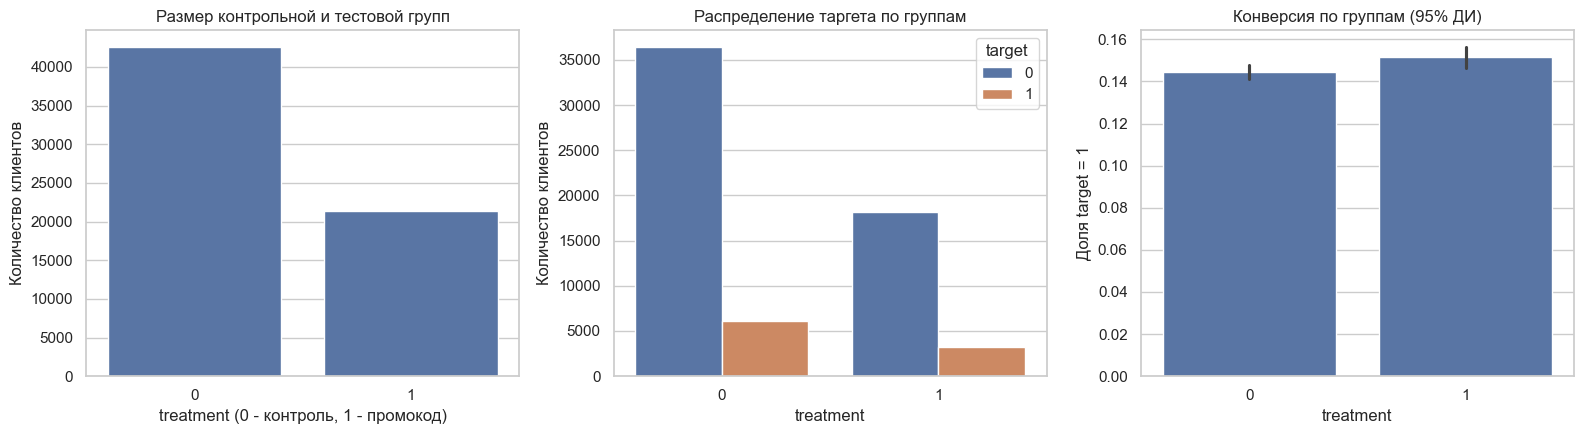

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.countplot(data=df, x='treatment', ax=axes[0])
axes[0].set_title('Размер контрольной и тестовой групп')
axes[0].set_xlabel('treatment (0 - контроль, 1 - промокод)')
axes[0].set_ylabel('Количество клиентов')

sns.countplot(data=df, x='treatment', hue='target', ax=axes[1])
axes[1].set_title('Распределение таргета по группам')
axes[1].set_xlabel('treatment')
axes[1].set_ylabel('Количество клиентов')

sns.barplot(data=df, x='treatment', y='target', ax=axes[2], errorbar=('ci', 95))
axes[2].set_title('Конверсия по группам (95% ДИ)')
axes[2].set_xlabel('treatment')
axes[2].set_ylabel('Доля target = 1')
plt.tight_layout()
plt.show()

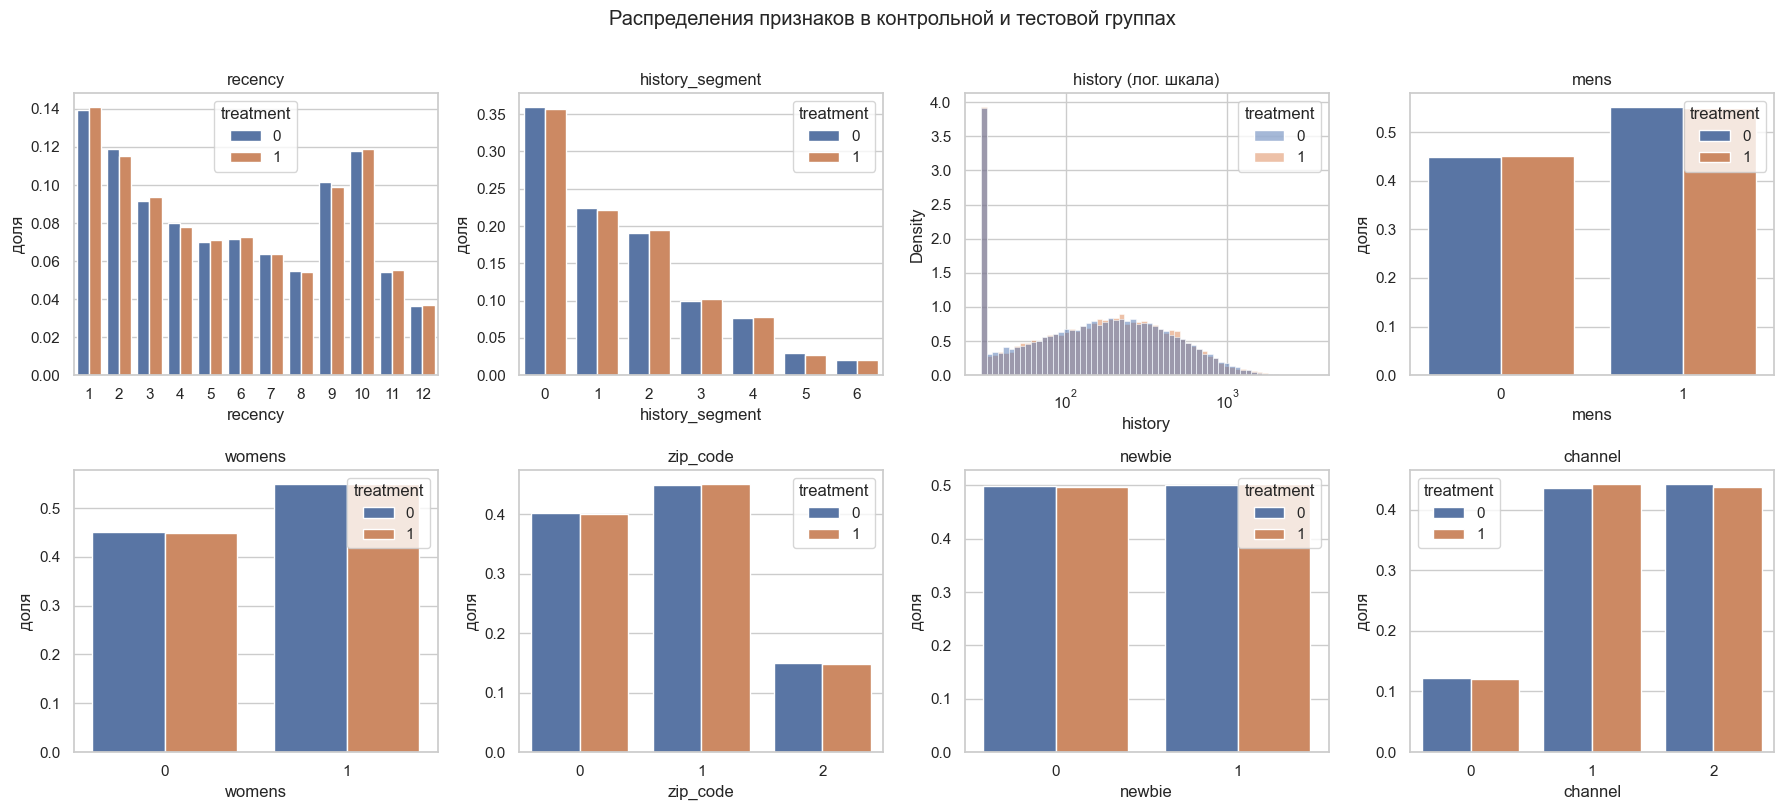

In [8]:
# распределения признаков в контроле и тесте
num_cols = ['recency', 'history_segment', 'history']
bin_cols = ['mens', 'womens', 'zip_code', 'newbie', 'channel']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, num_cols + bin_cols):
    if col == 'history':
        sns.histplot(data=df, x=col, hue='treatment', stat='density', common_norm=False,
                     bins=60, ax=ax, log_scale=True)
        ax.set_title('history (лог. шкала)')
    else:
        share = (df.groupby('treatment')[col].value_counts(normalize=True)
                   .rename('доля').reset_index())
        sns.barplot(data=share, x=col, y='доля', hue='treatment', ax=ax)
        ax.set_title(col)
plt.suptitle('Распределения признаков в контрольной и тестовой группах', y=1.01)
plt.tight_layout()
plt.show()

In [9]:
# mens и womens не бывают одновременно нулевыми
pd.crosstab(df['mens'], df['womens'], normalize=True)

womens,0,1
mens,,
0,0.0000,0.4490
1,0.4503,0.1008


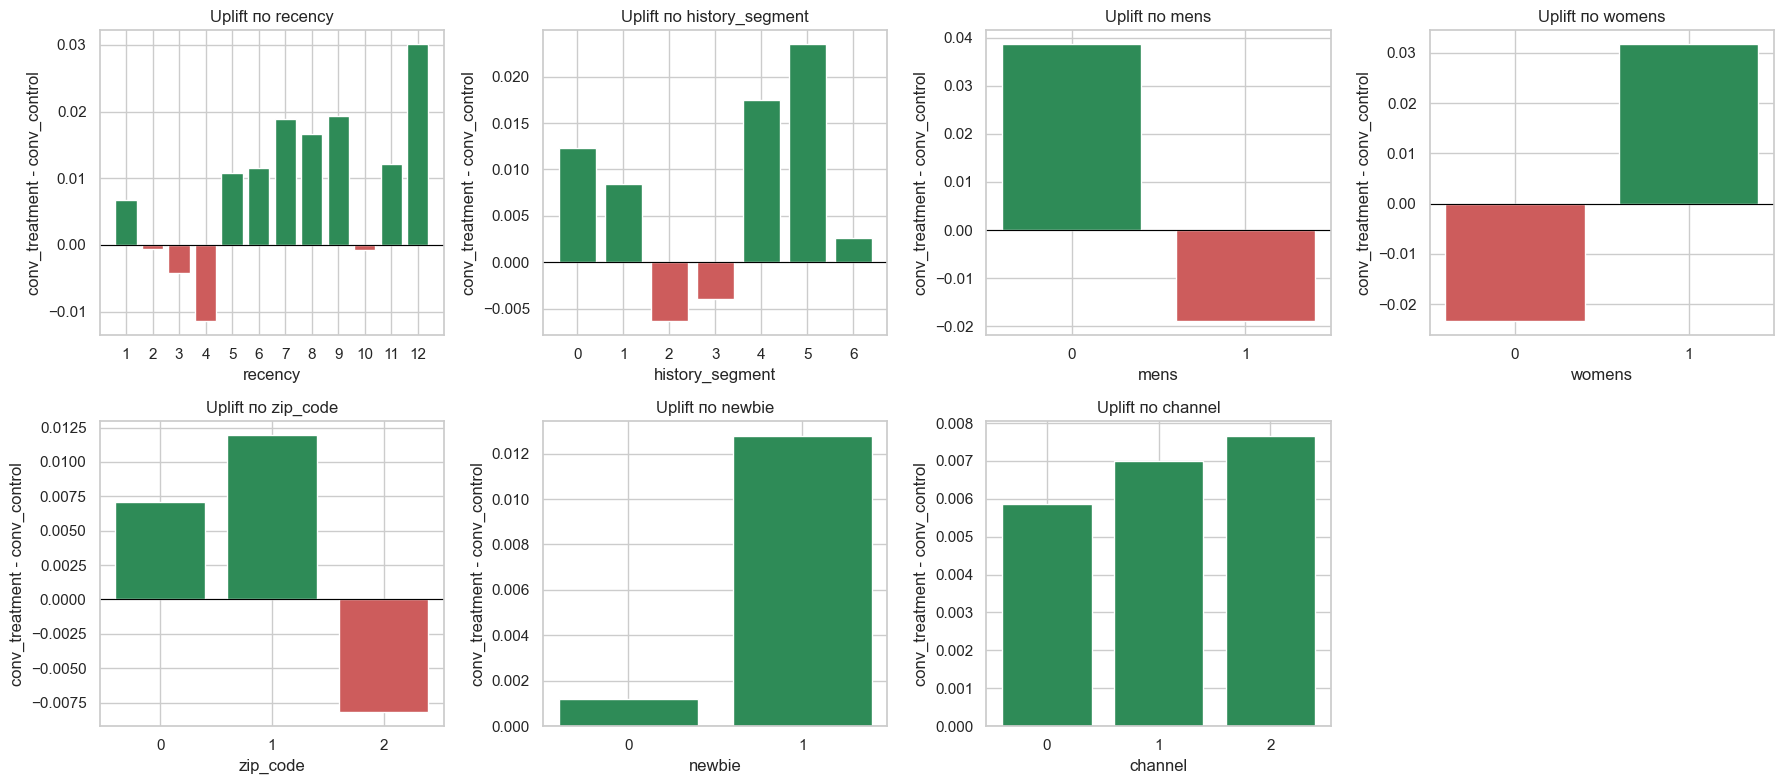

(      conv_control  conv_treatment  uplift      n
 mens                                             
 0           0.1312          0.1698  0.0386  28734
 1           0.1552          0.1363 -0.0189  35266,
         conv_control  conv_treatment  uplift      n
 womens                                             
 0             0.1342          0.1109 -0.0234  28818
 1             0.1528          0.1845  0.0317  35182)

In [10]:
# конверсия и наблюдаемый uplift в разрезе признаков
def uplift_by(col):
    g = df.groupby([col, 'treatment'])['target'].mean().unstack()
    g.columns = ['conv_control', 'conv_treatment']
    g['uplift'] = g['conv_treatment'] - g['conv_control']
    g['n'] = df.groupby(col).size()
    return g

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, ['recency', 'history_segment', 'mens', 'womens',
                               'zip_code', 'newbie', 'channel']):
    u = uplift_by(col)
    ax.bar(u.index.astype(str), u['uplift'], color=np.where(u['uplift'] > 0, 'seagreen', 'indianred'))
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(f'Uplift по {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('conv_treatment - conv_control')
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

uplift_by('mens'), uplift_by('womens')

**Выводы по EDA**

- В данных 64 000 клиентов, группы разбиты примерно 2:1: в контроле 42 613 человек, в тесте (получили промокод) 21 387.
- Конверсия в контроле 14.45%, в тестовой группе 15.14%. Средний эффект промокода - около +0.7 п.п., эффект слабый.
- Распределения признаков в двух группах практически совпадают, то есть рандомизация выглядит корректной (ниже проверю это тестами).
- `history` сильно скошен вправо: медиана около 158, максимум больше 3 300. `history_segment` - это по сути та же сумма, разбитая на 7 интервалов.
- `mens` и `womens` никогда не равны нулю одновременно: 45% клиентов покупали только мужское, 45% - только женское, 10% - и то и другое.
- Самое интересное - эффект промокода сильно различается по сегментам. У тех, кто не покупал мужское (`mens = 0`), uplift около +3.9 п.п., а у покупавших мужское - около -1.9 п.п. Похожая картина по `womens`: +3.2 п.п. против -2.3 п.п. Также заметно выше эффект у новых клиентов (`newbie = 1`) и у давно не покупавших (`recency` = 12).
- Раз эффект есть в одних сегментах и отрицательный в других, рассылать промокод всем невыгодно - имеет смысл строить uplift-модель и отбирать клиентов.

# Этап 2

### Проверка на статистическую значимость

**Выбор теста**

Целевая переменная бинарная (заказал / не заказал), поэтому сравниваю доли: z-тест для двух пропорций и, для контроля, хи-квадрат по таблице сопряженности 2x2. На выборке такого размера t-тест дал бы тот же результат, но для долей z-тест естественнее.

Гипотезы:
- H0: конверсия в тестовой и контрольной группах одинакова;
- H1: конверсии различаются (двусторонний тест), уровень значимости 0.05.

Дополнительно проверяю, что группы сопоставимы по признакам: для бинарных и категориальных признаков - хи-квадрат, для `recency`, `history_segment` и `history` - тест Манна-Уитни, так как `history` сильно скошен, а `recency` и `history_segment` порядковые.

In [11]:
control = df[df['treatment'] == 0]
treatment = df[df['treatment'] == 1]

# средние и стандартные отклонения по группам
pd.concat({'control mean': control.mean(), 'control std': control.std(),
           'treatment mean': treatment.mean(), 'treatment std': treatment.std()}, axis=1)

,control mean,control std,treatment mean,treatment std
recency,5.7617,3.5054,5.7678,3.5120
history_segment,1.4799,1.5474,1.4860,1.5387
history,241.8593,256.5747,242.5366,255.3329
mens,0.5521,0.4973,0.5489,0.4976
womens,0.5495,0.4975,0.5501,0.4975
zip_code,0.7484,0.6985,0.7487,0.6969
newbie,0.5017,0.5000,0.5032,0.5000
channel,1.3210,0.6791,1.3168,0.6765
treatment,0.0000,0.0000,1.0000,0.0000
target,0.1445,0.3516,0.1514,0.3584


In [12]:
# 1. Главная проверка: различается ли конверсия в группах (z-тест для двух долей)
successes = [treatment['target'].sum(), control['target'].sum()]
nobs = [len(treatment), len(control)]
z_stat, p_value = proportions_ztest(successes, nobs, alternative='two-sided')

conv_t, conv_c = treatment['target'].mean(), control['target'].mean()
print(f'Конверсия: treatment = {conv_t:.4f}, control = {conv_c:.4f}, разница = {conv_t - conv_c:.4f}')
print(f'z-тест для долей: z = {z_stat:.3f}, p-value = {p_value:.4f}')

# то же самое через хи-квадрат по таблице сопряжённости (для контроля)
chi2, p_chi2, _, _ = stats.chi2_contingency(pd.crosstab(df['treatment'], df['target']))
print(f'хи-квадрат: chi2 = {chi2:.3f}, p-value = {p_chi2:.4f}')

alpha = 0.05
print('\nРазница в конверсии статистически значима' if p_value < alpha
      else '\nРазница в конверсии статистически не значима')

Конверсия: treatment = 0.1514, control = 0.1445, разница = 0.0069
z-тест для долей: z = 2.339, p-value = 0.0193
хи-квадрат: chi2 = 5.417, p-value = 0.0199

Разница в конверсии статистически значима


In [13]:
# 2. Проверка рандомизации: признаки в группах не должны различаться
rows = []
for col in num_cols + bin_cols:
    a, b = control[col], treatment[col]
    if col in ('mens', 'womens', 'newbie', 'zip_code', 'channel'):
        p = stats.chi2_contingency(pd.crosstab(df['treatment'], df[col]))[1]
        test = 'хи-квадрат'
    else:
        p = stats.mannwhitneyu(a, b, alternative='two-sided').pvalue
        test = 'Манн-Уитни'
    rows.append({'признак': col, 'тест': test, 'mean control': a.mean(),
                 'mean treatment': b.mean(), 'p-value': p})
balance = pd.DataFrame(rows).set_index('признак')
balance['различие значимо'] = balance['p-value'] < alpha
balance

,тест,mean control,mean treatment,p-value,различие значимо
признак,,,,,
recency,Манн-Уитни,5.7617,5.7678,0.8221,False
history_segment,Манн-Уитни,1.4799,1.4860,0.3818,False
history,Манн-Уитни,241.8593,242.5366,0.3776,False
mens,хи-квадрат,0.5521,0.5489,0.4544,False
womens,хи-квадрат,0.5495,0.5501,0.8973,False
zip_code,хи-квадрат,0.7484,0.7487,0.8416,False
newbie,хи-квадрат,0.5017,0.5032,0.7264,False
channel,хи-квадрат,1.3210,1.3168,0.3111,False


**Результат**

p-value z-теста 0.019 (хи-квадрат дает 0.020), это меньше 0.05 - отвергаем H0. Промокод в среднем повышает конверсию примерно на 0.7 п.п. (с 14.45% до 15.14%), и это не случайность.

По всем признакам p-value больше 0.3, значимых различий между группами нет. Значит, эксперимент рандомизирован корректно и разницу в конверсии можно отнести к воздействию. Это также важно для uplift-моделей: они предполагают, что назначение промокода не зависит от признаков клиента.

## Построение корреляций

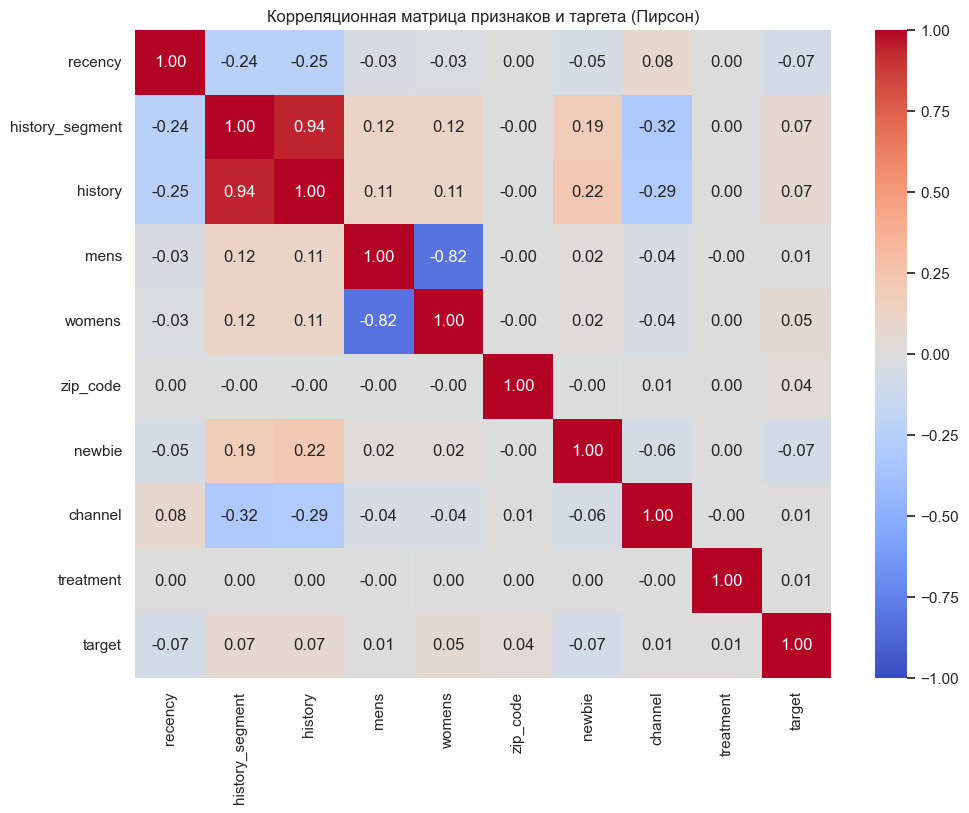

recency           -0.0748
newbie            -0.0739
history_segment    0.0697
history            0.0652
womens             0.0520
zip_code           0.0376
channel            0.0106
treatment          0.0092
mens               0.0067
Name: target, dtype: float64

In [14]:
corr = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Корреляционная матрица признаков и таргета (Пирсон)')
plt.show()

corr['target'].drop('target').sort_values(key=abs, ascending=False)

**Выводы по корреляциям**

- Сильнее всего связаны `history` и `history_segment` (0.94) - ожидаемо, один признак получен из другого. Для бустинга это не критично, но вклад в важность признаков будет делиться между ними.
- Заметные связи также у `channel` с `history_segment` (-0.32), у `recency` с `history` (-0.25) и у `newbie` с `history` (0.22).
- С таргетом все корреляции слабые, по модулю меньше 0.08: чаще заказывают те, кто покупал недавно (`recency` -0.075), не новые клиенты (`newbie` -0.074) и с большей суммой покупок.
- Корреляция `treatment` с таргетом всего 0.009 - средний эффект промокода мал на фоне общего разброса.

Важно помнить, что корреляция показывает связь признака с самим откликом, а не с эффектом от промокода. Например, `mens` с таргетом почти не коррелирует (0.007), но в EDA именно по нему эффект промокода различается сильнее всего. Поэтому признаки из модели не убираю.

## Этап 3

**Выбор бейзлайна**

В качестве бейзлайна беру S-learner (`SoloModel` из sklift) на CatBoost:
- данные из рандомизированного эксперимента, группы сбалансированы, поэтому подходят простые мета-модели без коррекции на propensity;
- эффект слабый (0.7 п.п.), а тестовая группа в два раза меньше контрольной. S-learner обучается на всей выборке сразу, и признак `treatment` работает как обычный признак, - на маленьком эффекте это обычно стабильнее, чем две отдельные модели;
- CatBoost хорошо работает на табличных данных без особой предобработки и умеет нативно обрабатывать категориальные признаки (`zip_code`, `channel`).

Для сравнения дальше обучаю T-learner и X-learner. Основная метрика - Uplift@30 (эффект в топ-30% клиентов по прогнозу), дополнительно смотрю на uplift AUC и Qini AUC.

### Советы по обучению и инференсу моделей
1. Некоторые uplift модели из библиотеки `causalml` будут требовать категориальные значения воздействия. Для этого используйте маппинг
#### Пример использования маппинга
```python
treatment_mapping = {
    0: 'control',
    1: 'treatment'
}
treatment_train_mapped = treatment_train.map(treatment_mapping)
treatment_test_mapped = treatment_test.map(treatment_mapping)
```

2. При вызове метода `.predict` и получения метрик для тестовой выборки не забывайте применять к прогнозам метод `squeeze()`, чтобы преобразовать многомерный массив в одномерный, что поможет получить адекватные метрики.

3. Для воспроизводимости результатов и объективной оценки не забывайте применять `random_state=42` для моделей, а также при разделении выборки

### Разбиение выборки на тренировочную и тестовую

In [15]:
X = df.drop(columns=['treatment', 'target'])
y = df['target']
treat = df['treatment']

X_train, X_test, y_train, y_test, treatment_train, treatment_test = train_test_split(
    X, y, treat, test_size=0.2, stratify=df[['treatment', 'target']], random_state=RANDOM_STATE)

print('train:', X_train.shape, ' test:', X_test.shape)
pd.DataFrame({
    'train': pd.crosstab(treatment_train, y_train, normalize=True).stack(),
    'test': pd.crosstab(treatment_test, y_test, normalize=True).stack(),
})

train: (51200, 8)  test: (12800, 8)


train   test
treatment target              
0         0      0.5696 0.5696
          1      0.0962 0.0962
1         0      0.2836 0.2836
          1      0.0506 0.0506

### Обучение выбранного бейзлайна

In [16]:
# общие гиперпараметры базового алгоритма - одинаковые для всех трёх моделей части 1
CB_PARAMS = dict(iterations=300, depth=6, learning_rate=0.05,
                 random_state=RANDOM_STATE, verbose=0, allow_writing_files=False)

def get_metrics(uplift, name):
    uplift = np.asarray(uplift).squeeze()
    return pd.Series({
        'uplift AUC': uplift_auc_score(y_test, uplift, treatment_test),
        'Qini AUC': qini_auc_score(y_test, uplift, treatment_test),
        'Uplift@30': uplift_at_k(y_test, uplift, treatment_test, strategy='overall', k=0.3),
    }, name=name)

# baseline: S-learner, treatment подаётся в модель как обычный признак
s_learner = SoloModel(CatBoostClassifier(**CB_PARAMS))
s_learner.fit(X_train, y_train, treatment_train)
uplift_s = s_learner.predict(X_test).squeeze()

### Расчет метрик для выбранного бейзлайна на тестовой выборке

In [17]:
results = pd.DataFrame([get_metrics(uplift_s, 'S-learner (baseline)')])
results

,uplift AUC,Qini AUC,Uplift@30
S-learner (baseline),0.0259,0.0582,0.0397


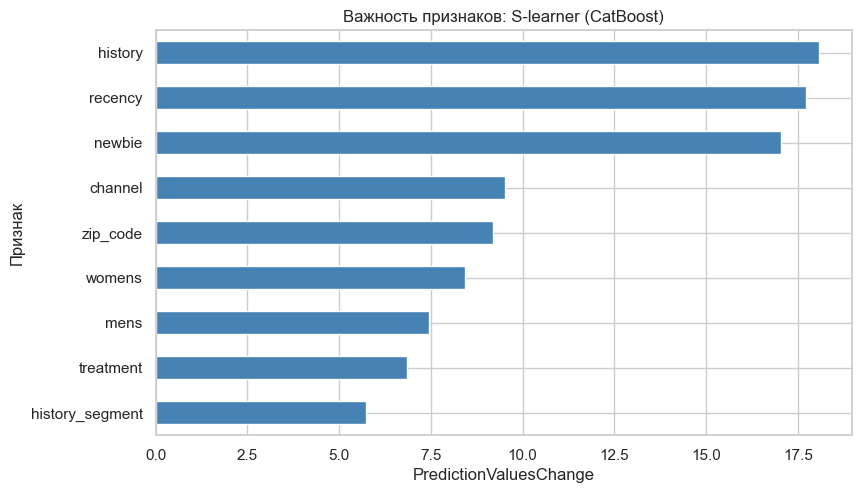

In [18]:
# важность признаков baseline; SoloModel добавляет столбец treatment последним
fi_s = pd.Series(s_learner.estimator.feature_importances_,
                 index=list(X_train.columns) + ['treatment']).sort_values()

plt.figure(figsize=(8, 5))
fi_s.plot.barh(color='steelblue')
plt.title('Важность признаков: S-learner (CatBoost)')
plt.xlabel('PredictionValuesChange')
plt.ylabel('Признак')
plt.show()

# Обучение 2 моделей 

### Обучение модели 1

In [19]:
# модель 1: T-learner - отдельные модели для теста и контроля, uplift = разность прогнозов
t_learner = TwoModels(estimator_trmnt=CatBoostClassifier(**CB_PARAMS),
                      estimator_ctrl=CatBoostClassifier(**CB_PARAMS),
                      method='vanilla')
t_learner.fit(X_train, y_train, treatment_train)
uplift_t = t_learner.predict(X_test).squeeze()

### Получение метрик по модели 1

In [20]:
results = pd.concat([results, get_metrics(uplift_t, 'T-learner').to_frame().T])
results

,uplift AUC,Qini AUC,Uplift@30
S-learner (baseline),0.0259,0.0582,0.0397
T-learner,0.0200,0.0449,0.0361


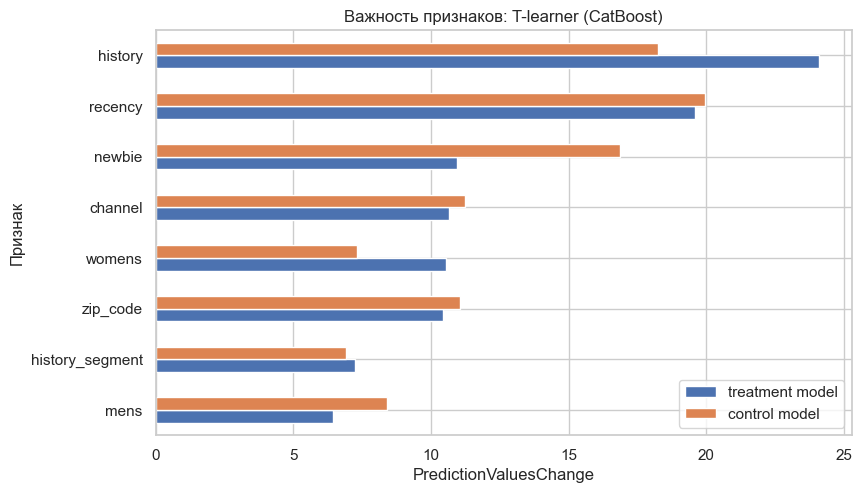

In [21]:
fi_t = pd.DataFrame({
    'treatment model': t_learner.estimator_trmnt.feature_importances_,
    'control model': t_learner.estimator_ctrl.feature_importances_,
}, index=X_train.columns).sort_values('treatment model')

fi_t.plot.barh(figsize=(8, 5))
plt.title('Важность признаков: T-learner (CatBoost)')
plt.xlabel('PredictionValuesChange')
plt.ylabel('Признак')
plt.show()

### Обучение модели 2

In [22]:
# модель 2: X-learner из causalml.
# Эксперимент рандомизированный, поэтому propensity score - просто доля тестовой группы.
treatment_mapping = {0: 'control', 1: 'treatment'}
treatment_train_mapped = treatment_train.map(treatment_mapping)

p_train = np.full(len(X_train), treatment_train.mean())
p_test = np.full(len(X_test), treatment_train.mean())

x_learner = BaseXClassifier(outcome_learner=CatBoostClassifier(**CB_PARAMS),
                            effect_learner=CatBoostRegressor(**CB_PARAMS),
                            control_name='control')
x_learner.fit(X_train.values, treatment_train_mapped.values, y_train.values, p=p_train)
uplift_x = x_learner.predict(X_test.values, p=p_test).squeeze()

### Получение метрик по модели 2

In [23]:
results = pd.concat([results, get_metrics(uplift_x, 'X-learner').to_frame().T])
results

,uplift AUC,Qini AUC,Uplift@30
S-learner (baseline),0.0259,0.0582,0.0397
T-learner,0.0200,0.0449,0.0361
X-learner,0.0208,0.0469,0.0314


**Сравнение моделей**

| Модель | uplift AUC | Qini AUC | Uplift@30 |
|---|---|---|---|
| S-learner | 0.0259 | 0.0582 | 0.0397 |
| T-learner | 0.0200 | 0.0449 | 0.0361 |
| X-learner | 0.0208 | 0.0469 | 0.0314 |

S-learner лучше по всем трем метрикам. Почему T- и X-learner проигрывают:
- в T-learner модель для тестовой группы учится всего примерно на 17 тыс. клиентов. Uplift получается как разность двух прогнозов, у каждого из которых своя ошибка, и при эффекте в доли процента эта ошибка оказывается сравнима с самим эффектом;
- X-learner строится поверх тех же двух моделей и дальше учится на восстановленных индивидуальных эффектах, которые получаются еще более шумными.

Дальше улучшаю S-learner.

# Часть 2

## Этап 1
Улучшите бейзлайн выбранной модели

**План улучшения**

Подбирать параметры по тестовой выборке нельзя - так метрика на тесте станет завышенной. Поэтому качество при подборе оцениваю кросс-валидацией на 3 фолдах только по train. Фолды стратифицированы сразу по `treatment` и `target`, чтобы в каждом были обе группы и обе метки в тех же долях. Метрика - Uplift@30, как и в первой части. Тест используется один раз, для итоговой оценки.

Порядок:
1. CV-оценка бейзлайна (точка отсчета);
2. проверка нескольких новых признаков;
3. подбор гиперпараметров CatBoost через Optuna;
4. обучение финальной модели на всем train и оценка на тесте.

In [24]:
# стратификация фолдов по комбинации treatment + target, как и при разбиении на train/test
strat_train = y_train.astype(str) + '_' + treatment_train.astype(str)
CAT_FEATURES = ['zip_code', 'channel']

def uplift_at_30(y_true, uplift, treatment):
    return uplift_at_k(y_true, np.asarray(uplift).squeeze(), treatment, strategy='overall', k=0.3)

def make_s_learner(params, use_cat=False):
    p = dict(random_state=RANDOM_STATE, verbose=0, thread_count=-1, allow_writing_files=False)
    p.update(params)
    return SoloModel(CatBoostClassifier(**p, cat_features=CAT_FEATURES if use_cat else None))

def cv_uplift_at_30(make_model, X_tr, n_splits=3):
    """Средний Uplift@30 на валидационных фолдах внутри train."""
    scores = []
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=RANDOM_STATE)
    for tr_idx, val_idx in skf.split(X_tr, strat_train):
        model = make_model()
        model.fit(X_tr.iloc[tr_idx], y_train.iloc[tr_idx], treatment_train.iloc[tr_idx])
        scores.append(uplift_at_30(y_train.iloc[val_idx], model.predict(X_tr.iloc[val_idx]),
                                   treatment_train.iloc[val_idx]))
    return np.mean(scores), np.std(scores)

base_params = dict(iterations=300, depth=6, learning_rate=0.05)
m, s = cv_uplift_at_30(lambda: make_s_learner(base_params), X_train)
print(f'Baseline S-learner, Uplift@30 на CV: {m:.4f} ± {s:.4f}')

Baseline S-learner, Uplift@30 на CV: 0.0404 ± 0.0017


#### Генерация признаков (опционально)

In [25]:
def add_features(data):
    data = data.copy()
    # mens/womens никогда не равны нулю одновременно, поэтому это фактически 3 типа покупателя
    data['buyer_type'] = data['mens'] + 2 * data['womens']   # 1 - только мужское, 2 - только женское, 3 - оба
    data['log_history'] = np.log1p(data['history'])
    data['history_per_month'] = data['history'] / data['recency']
    return data

X_train_fe = add_features(X_train)

m_fe, s_fe = cv_uplift_at_30(lambda: make_s_learner(base_params), X_train_fe)
print(f'S-learner без новых признаков: {m:.4f} ± {s:.4f}')
print(f'S-learner с новыми признаками: {m_fe:.4f} ± {s_fe:.4f}')

S-learner без новых признаков: 0.0404 ± 0.0017
S-learner с новыми признаками: 0.0360 ± 0.0026


**Результат**

С новыми признаками Uplift@30 на кросс-валидации упал: 0.0360 против 0.0404 без них. Новые признаки почти полностью дублируют старые (`log_history` - монотонное преобразование `history`, на деревья не влияет, `buyer_type` - комбинация `mens` и `womens`), и модель только сильнее подстраивается под шум. Поэтому дальше оставляю исходный набор признаков.

### Подбор гиперпараметров

In [26]:
import optuna
from optuna import create_study
from optuna.samplers import TPESampler
from sklift.metrics import uplift_at_k

optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = dict(
        iterations=trial.suggest_int('iterations', 100, 800, step=50),
        depth=trial.suggest_int('depth', 2, 8),
        learning_rate=trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        l2_leaf_reg=trial.suggest_float('l2_leaf_reg', 1, 30, log=True),
        min_data_in_leaf=trial.suggest_int('min_data_in_leaf', 1, 500, log=True),
    )
    # zip_code и channel - номинальные признаки, проверяем, помогает ли CatBoost их кодирование
    use_cat = trial.suggest_categorical('use_cat', [False, True])

    # Uplift@30 считаем на валидационных фолдах train, а не на тесте:
    # иначе гиперпараметры подстроятся под конкретную тестовую выборку и оценка будет завышена
    uplift_at_30, _ = cv_uplift_at_30(lambda: make_s_learner(params, use_cat), X_train)
    return uplift_at_30

# Создаем и запускаем исследование
study = create_study(direction='maximize', sampler=TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=40)

# Выводим лучшие гиперпараметры
print("Best hyperparameters: ", study.best_params)
print("Best score: ", study.best_value)

Best hyperparameters:  {'iterations': 100, 'depth': 7, 'learning_rate': 0.10708418653412762, 'l2_leaf_reg': 14.728562654282605, 'min_data_in_leaf': 3, 'use_cat': True}
Best score:  0.045358669384972246


In [27]:
study.trials_dataframe().sort_values('value', ascending=False).head(10)

,number,value,datetime_start,datetime_complete,duration,params_depth,params_iterations,params_l2_leaf_reg,params_learning_rate,params_min_data_in_leaf,params_use_cat,state
13,13,0.0454,2026-10-22 21:28:12.644701,2026-10-22 21:28:13.327639,0 days 00:00:00.682938,7,100,14.7286,0.1071,3,True,COMPLETE
35,35,0.0443,2026-10-22 21:29:27.876432,2026-10-22 21:29:29.005148,0 days 00:00:01.128716,8,150,12.3760,0.0493,1,True,COMPLETE
7,7,0.0433,2026-10-22 21:27:53.405041,2026-10-22 21:27:57.393495,0 days 00:00:03.988454,8,200,24.4205,0.1020,242,True,COMPLETE
39,39,0.0428,2026-10-22 21:29:35.128652,2026-10-22 21:29:36.363721,0 days 00:00:01.235069,8,150,8.8247,0.0106,1,True,COMPLETE
21,21,0.0428,2026-10-22 21:28:52.687422,2026-10-22 21:28:53.481674,0 days 00:00:00.794252,8,100,8.4484,0.0154,6,True,COMPLETE
23,23,0.0424,2026-10-22 21:28:56.817038,2026-10-22 21:28:57.788333,0 days 00:00:00.971295,7,150,20.9668,0.0960,5,True,COMPLETE
6,6,0.0422,2026-10-22 21:27:52.599974,2026-10-22 21:27:53.405013,0 days 00:00:00.805039,8,100,9.5198,0.0217,4,True,COMPLETE
19,19,0.0420,2026-10-22 21:28:44.751073,2026-10-22 21:28:45.526269,0 days 00:00:00.775196,8,100,4.2718,0.0427,24,True,COMPLETE
16,16,0.0415,2026-10-22 21:28:23.064066,2026-10-22 21:28:33.985601,0 days 00:00:10.921535,7,600,29.5963,0.0399,35,True,COMPLETE
25,25,0.0414,2026-10-22 21:28:58.935292,2026-10-22 21:29:02.972924,0 days 00:00:04.037632,6,250,7.8517,0.0370,11,True,COMPLETE


In [28]:
# финальная модель: лучшие гиперпараметры, обучение на всём train, оценка на test
best_params = dict(study.best_params)
best_use_cat = best_params.pop('use_cat')

final_model = make_s_learner(best_params, best_use_cat)
final_model.fit(X_train, y_train, treatment_train)
uplift_final = final_model.predict(X_test).squeeze()

results = pd.concat([results, get_metrics(uplift_final, 'S-learner, Optuna').to_frame().T])
results

,uplift AUC,Qini AUC,Uplift@30
S-learner (baseline),0.0259,0.0582,0.0397
T-learner,0.0200,0.0449,0.0361
X-learner,0.0208,0.0469,0.0314
"S-learner, Optuna",0.0291,0.0653,0.0438


In [29]:
print(f"Финальный Uplift@30 на тесте: {results.loc['S-learner, Optuna', 'Uplift@30']:.4f}")

Финальный Uplift@30 на тесте: 0.0438


## Этап 2

### Визуализация результатов

In [30]:
from utils import custom_uplift_by_percentile

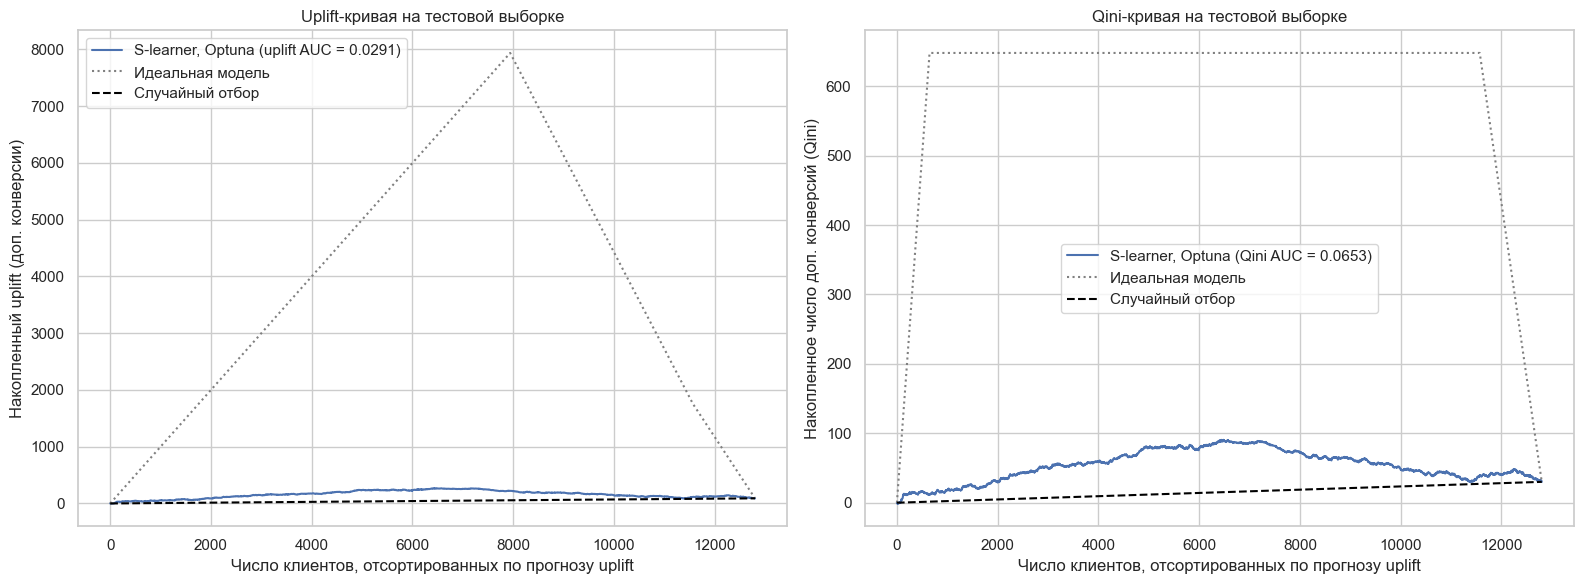

In [31]:
# sklift.viz не импортируется вместе с scikit-learn 1.6.1 (нет check_matplotlib_support),
# поэтому кривые строю сам по точкам из sklift.metrics
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

x, yv = uplift_curve(y_test, uplift_final, treatment_test)
xp, yp = perfect_uplift_curve(y_test, treatment_test)
axes[0].plot(x, yv, label=f'S-learner, Optuna (uplift AUC = {uplift_auc_score(y_test, uplift_final, treatment_test):.4f})')
axes[0].plot(xp, yp, color='gray', linestyle=':', label='Идеальная модель')
axes[0].plot([0, x[-1]], [0, yv[-1]], color='black', linestyle='--', label='Случайный отбор')
axes[0].set_title('Uplift-кривая на тестовой выборке')
axes[0].set_xlabel('Число клиентов, отсортированных по прогнозу uplift')
axes[0].set_ylabel('Накопленный uplift (доп. конверсии)')
axes[0].legend()

x, yv = qini_curve(y_test, uplift_final, treatment_test)
xp, yp = perfect_qini_curve(y_test, treatment_test)
axes[1].plot(x, yv, label=f'S-learner, Optuna (Qini AUC = {qini_auc_score(y_test, uplift_final, treatment_test):.4f})')
axes[1].plot(xp, yp, color='gray', linestyle=':', label='Идеальная модель')
axes[1].plot([0, x[-1]], [0, yv[-1]], color='black', linestyle='--', label='Случайный отбор')
axes[1].set_title('Qini-кривая на тестовой выборке')
axes[1].set_xlabel('Число клиентов, отсортированных по прогнозу uplift')
axes[1].set_ylabel('Накопленное число доп. конверсий (Qini)')
axes[1].legend()
plt.tight_layout()
plt.show()

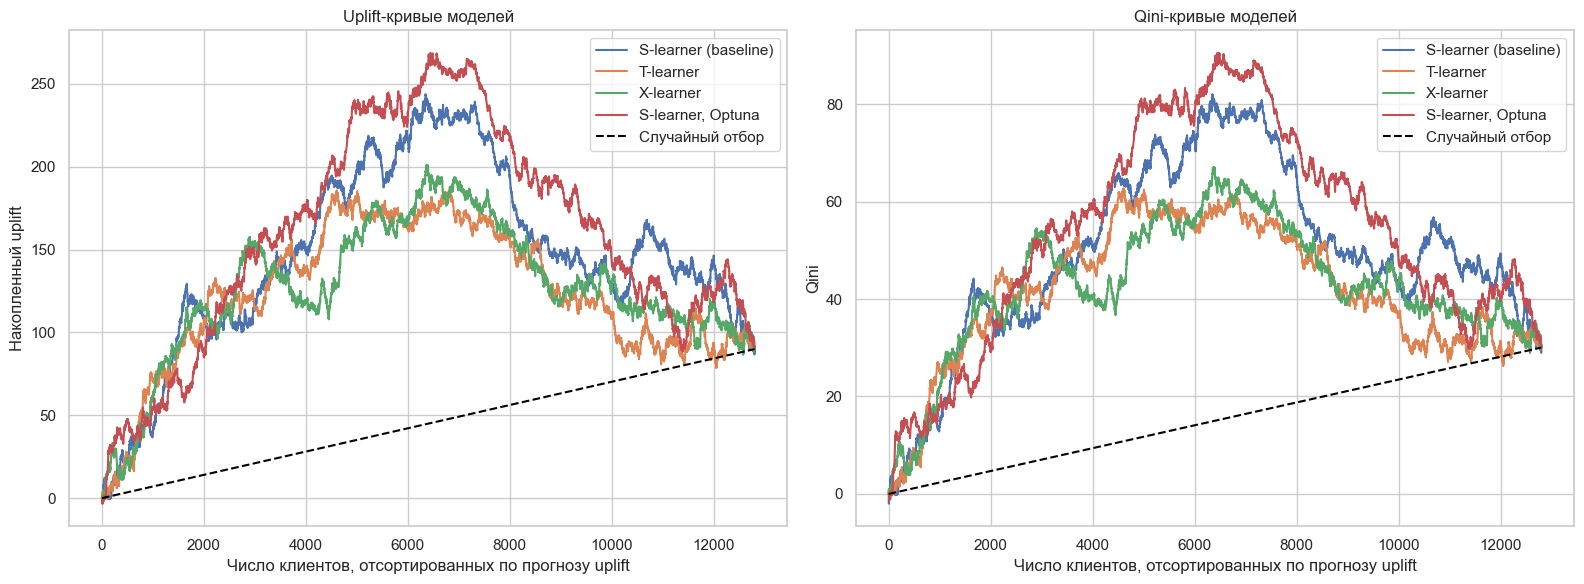

In [32]:
# те же кривые без идеальной модели, чтобы был виден разрыв между моделями и случайным отбором
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for name, u in [('S-learner (baseline)', uplift_s), ('T-learner', uplift_t),
                ('X-learner', uplift_x), ('S-learner, Optuna', uplift_final)]:
    x, yv = uplift_curve(y_test, u, treatment_test)
    axes[0].plot(x, yv, label=name)
    x, yv = qini_curve(y_test, u, treatment_test)
    axes[1].plot(x, yv, label=name)
for ax, title, ylabel in [(axes[0], 'Uplift-кривые моделей', 'Накопленный uplift'),
                          (axes[1], 'Qini-кривые моделей', 'Qini')]:
    ax.plot([0, x[-1]], [0, ax.lines[-1].get_ydata()[-1]], color='black', linestyle='--', label='Случайный отбор')
    ax.set_title(title)
    ax.set_xlabel('Число клиентов, отсортированных по прогнозу uplift')
    ax.set_ylabel(ylabel)
    ax.legend()
plt.tight_layout()
plt.show()

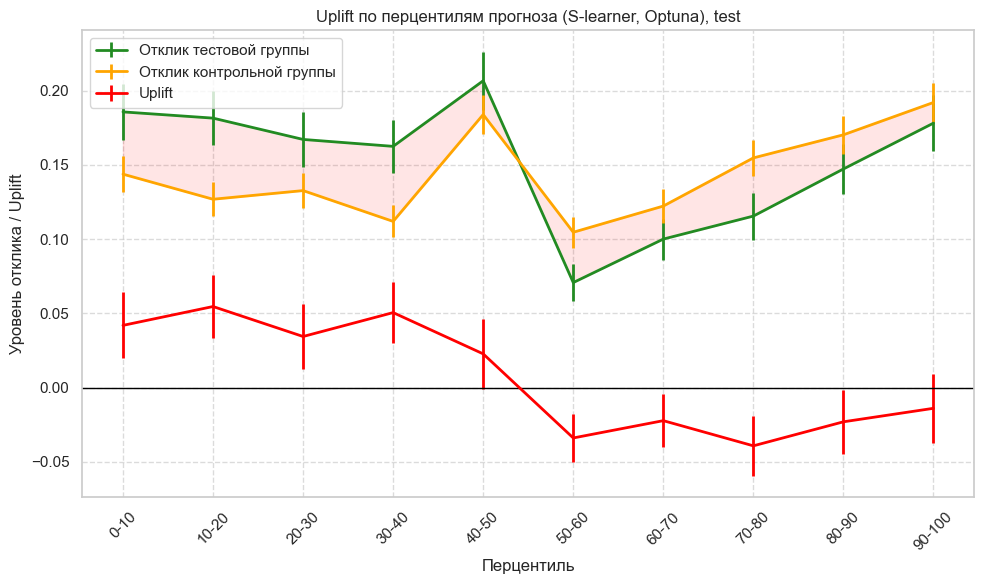

In [33]:
fig = custom_uplift_by_percentile(y_test, uplift_final, treatment_test, kind='line', bins=10,
                                  title='Uplift по перцентилям прогноза (S-learner, Optuna), test')
plt.show()

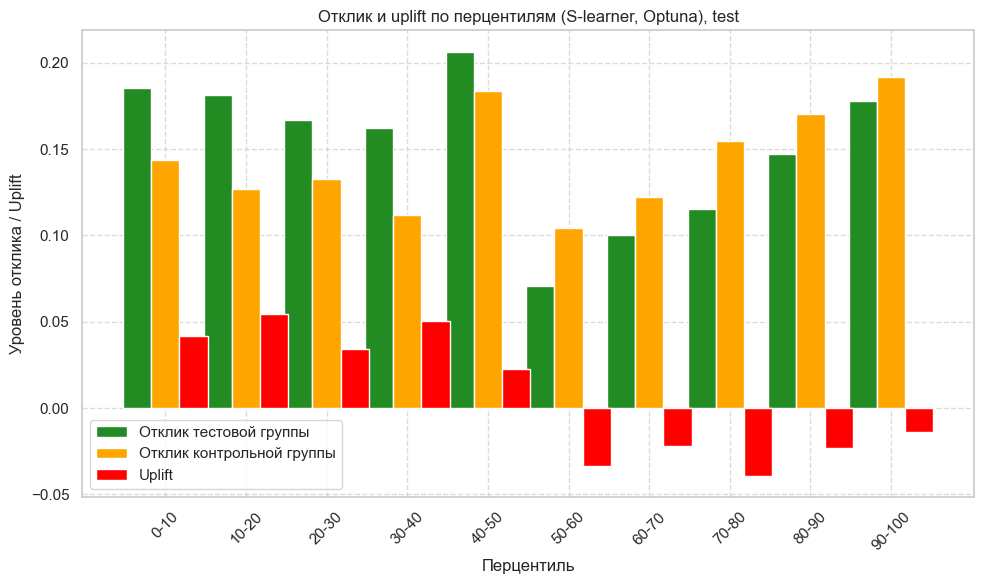

In [34]:
fig = custom_uplift_by_percentile(y_test, uplift_final, treatment_test, kind='bar', bins=10,
                                  title='Отклик и uplift по перцентилям (S-learner, Optuna), test')
plt.show()

**Итоги**

| Модель | uplift AUC | Qini AUC | Uplift@30 |
|---|---|---|---|
| S-learner (бейзлайн) | 0.0259 | 0.0582 | 0.0397 |
| S-learner после Optuna | 0.0291 | 0.0653 | 0.0438 |

После подбора гиперпараметров все три метрики выросли на 10-12%. Uplift@30 на тесте 0.0438 близок к оценке на кросс-валидации (0.0454), значит модель не переобучена под тест. Лучшие параметры - мало деревьев (100), но довольно глубоких (7) и с сильной регуляризацией (`l2_leaf_reg` около 15), а `zip_code` и `channel` лучше передавать как категориальные. Это логично: сигнал слабый, и сложная модель быстро начинает учить шум.

Что видно на графиках:
- uplift- и Qini-кривые лежат выше случайного отбора, но до идеальной модели далеко - для такой задачи это нормально;
- накопленный эффект растет примерно до 50% клиентов, а потом падает: второй половине клиентов промокод в среднем вредит;
- по перцентилям в первых 40% uplift стабильно положительный, от +3.4 до +5.5 п.п. С 50-го перцентиля он отрицательный, от -1.4 до -3.9 п.п.

Практический вывод: промокод стоит отправлять примерно 30-40% клиентов с наибольшим прогнозом uplift. В топ-30% промокод дает около +4.4 п.п. к конверсии, а при рассылке всем эффект в среднем всего +0.7 п.п.

Что можно попробовать дальше:
- ансамбль из нескольких моделей (S-, T-learner, uplift-лес), усредняя ранги прогнозов;
- `UpliftRandomForestClassifier` из causalml с подбором параметров;
- class transformation с весами для несбалансированных групп;
- больше итераций Optuna и больше фолдов, чтобы снизить шум в оценке;
- собрать больше данных по тестовой группе - сейчас она в два раза меньше контрольной, и это главное ограничение.

# Этап 3

In [35]:
# Класс для инференса модели
class UpliftModelInference:
    """
    Класс для инференса uplift модели.
    """
    
    def __init__(self, model, feature_names, logger=None):
        """
        Инициализация класса.
        
        Аргументы:
            model: Обученная модель uplift
            feature_names: Список признаков для предсказания 
            logger: Объект для логирования (по умолчанию None)
        """
        self.model = model
        self.feature_names = list(feature_names)
        self.logger = logger
        
        if self.logger:
            self.logger.info("Модель UpliftModel инициализирована с признаками: %s", feature_names)

    def _transform_data(self, X):
        """
        Преобразование данных для модели.
        
        Аргументы:
            X: pandas.DataFrame с признаками
        """
        if self.logger:
            self.logger.debug("Преобразование входных данных размерности %s", X.shape)

        # новые признаки в финальной модели не используются,
        # поэтому только оставляем нужные столбцы в том порядке, в котором училась модель
        X = X[self.feature_names]

        return X
    
    def predict(self, X):
        """
        Получение предсказаний uplift.
        
        Аргументы:
            X: pandas.DataFrame с признаками
            
        Возвращает:
            numpy.array с предсказанными значениями uplift
        """
        # Проверяем, что датафрейм не пустой
        if X.empty:
            if self.logger:
                self.logger.error("Предоставлен пустой датафрейм")
            return None
            
        # Проверяем наличие пропущенных значений
        if X.isnull().any().any():
            if self.logger:
                self.logger.error("Входные данные содержат пропущенные значения")
            return [None]*len(X)
        
        if self.logger:
            self.logger.info("Выполняем предсказания для данных размерности %s", X.shape)

        # Проверяем наличие всех необходимых признаков
        missing_features = set(self.feature_names) - set(X.columns)
        if missing_features:
            error_msg = f"Отсутствуют признаки: {missing_features}"
            if self.logger:
                self.logger.error(error_msg)

            return [None]*len(X)
        
        # Преобразуем данные для модели
        if self.logger:
            self.logger.debug("Начинаем преобразование данных")
        X = self._transform_data(X)
        
        # Вычисляем uplift
        if self.logger:
            self.logger.debug("Выполняем предсказания модели")
        

        # SoloModel сама считает P(y=1 | treatment=1) - P(y=1 | treatment=0)
        uplift = np.asarray(self.model.predict(X)).reshape(-1)
        
        if self.logger:
            self.logger.info("Предсказания успешно завершены")
            
        return uplift


In [36]:
model = UpliftModelInference(model=final_model,
                             feature_names=X_train.columns.tolist())

In [37]:
test_data = pd.DataFrame({
            'recency': [1, 2, 3],
            'history_segment': [1, 2, 3], 
            'history': [100, 200, 300],
            'mens': [1, 0, 1],
            'womens': [0, 1, 0],
            'zip_code': [1, 0, 1],
            'newbie': [0, 1, 0],
            'channel': [1, 2, 0]
        })

In [38]:
# проверка работы класса
model.predict(test_data)

array([-0.02248332,  0.02329004, -0.03843903])

In [39]:
# проверки на некорректных данных
print(model.predict(test_data.iloc[0:0]))
print(model.predict(test_data.drop(columns=['channel'])))
print(model.predict(test_data.assign(history=[100, None, 300])))

# на тестовой выборке результат совпадает с прогнозом финальной модели
print(np.allclose(model.predict(X_test), uplift_final))

None
[None, None, None]
[None, None, None]
True
